# 04 - Explainability (SHAP-style global + local, LIME-style local)
CRISP-DM phases 5-6. **What these methods are:** the `shap` and `lime` packages could not be installed in the build environment, so `src/explain/` contains (a) a model-agnostic **permutation-sampling Shapley** explainer (the estimator behind SHAP for any model; contributions sum exactly to f(x) minus the baseline, verified in tests) and (b) a **LIME-style** local surrogate whose interpretable representation is "feature keeps its value / is replaced by a background value". If `shap`/`lime` are installed, `src/explain/shapley.py::shap_tree_values` gives an independent check. Explanations describe the model, not causes: a high contribution does not mean changing that behaviour will change the purchase.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
sys.path.insert(0, str(Path.cwd()))
from src.config import load_settings
from src.data.loader import load_sessions, stratified_split
from src.features.engineering import add_engineered_features
from src.utils import metrics as M
S = load_settings()
df = load_sessions(S)

In [2]:
from src.serving.predictor import PurchasePredictor
E = json.load(open(S.path('reports_dir') / 'explain_results.json'))
pred = PurchasePredictor.load(settings=S)
print('model:', pred.meta['model'], '| features explained:', len(pred.features))
g = pd.DataFrame(E['global']); g.round(4).head(10)

model: LogisticRegression | features explained: 10


,feature,mean_abs_phi,mean_phi
0,ProductRelated,0.0976,-0.0179
1,ExitRates,0.0403,-0.0087
2,Administrative,0.0148,-0.0070
3,BounceRates,0.0107,0.0009
4,Informational_Duration,0.0086,0.0008
5,Administrative_Duration,0.0078,0.0045
6,Browser,0.0058,-0.0013
7,VisitorType,0.0036,-0.0019
8,ProductRelated_Duration,0.0033,-0.0010
9,Informational,0.0004,-0.0000


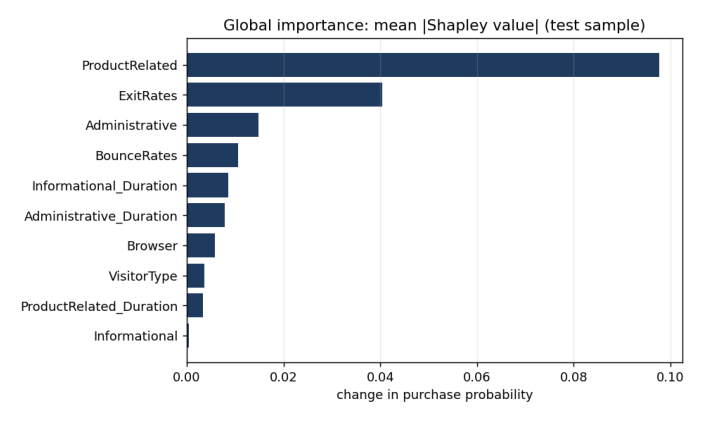

In [3]:
import matplotlib.image as mpimg
plt.figure(figsize=(8, 5)); plt.imshow(mpimg.imread(S.path('figures_dir') / 'shapley_global.png')); plt.axis('off'); plt.show()

**Takeaway:** ProductRelated (mean |effect| about 10 percentage points of purchase probability) and ExitRates (about 4 points) account for almost all of the model's behaviour; everything else is 1-1.5 points or less. Ranking agreement with permutation importance (notebook 02): Spearman 0.89.

In [4]:
rows = []
for name, v in E['local'].items():
    print(f"--- {name}: model P(purchase) = {v['probability']:.3f}, baseline {v['base']:.3f}, actually converted: {v['actual_converted']}, Shapley efficiency gap {v['efficiency_gap']:.1e}")
    print('  Shapley :', {k: round(x, 3) for k, x in v['shapley'].items()})
    print('  LIME    :', {k: round(x, 3) for k, x in list(v['lime'].items())[:5]}, f"(local fit R2 {v['lime_r2']:.2f})")

--- highest: model P(purchase) = 0.910, baseline 0.197, actually converted: 1, Shapley efficiency gap 2.2e-16
  Shapley : {'ProductRelated': 0.573, 'ExitRates': 0.096, 'Administrative': 0.017, 'BounceRates': 0.016, 'Informational_Duration': 0.014, 'Administrative_Duration': -0.01}
  LIME    : {'ProductRelated': 0.571, 'ExitRates': 0.119, 'BounceRates': 0.031, 'Administrative': 0.024, 'Informational_Duration': 0.017} (local fit R2 0.84)
--- near_threshold: model P(purchase) = 0.125, baseline 0.197, actually converted: 1, Shapley efficiency gap -1.4e-17
  Shapley : {'ProductRelated': -0.102, 'Browser': 0.018, 'Administrative': 0.014, 'ExitRates': -0.013, 'Informational_Duration': 0.012, 'BounceRates': 0.007}
  LIME    : {'ProductRelated': -0.094, 'Administrative': 0.019, 'BounceRates': 0.018, 'Browser': 0.015, 'Informational_Duration': 0.012} (local fit R2 0.19)
--- lowest: model P(purchase) = 0.000, baseline 0.197, actually converted: 0, Shapley efficiency gap 0.0e+00
  Shapley : {'Prod

**Takeaway:** for the highest-scored session ProductRelated alone adds about +57 points; for the lowest it subtracts about 11 points together with ExitRates (-6). The two methods name the same top feature, but check LIME's local R2: when it is low (0.2-0.3 for two of the three examples) the linear surrogate fits the model poorly and the LIME numbers should be treated as a rough second opinion, not a measurement.

In [5]:
print('Shapley vs LIME-style over', E['shapley_vs_lime']['n'], 'sessions:', {k: round(v, 3) for k, v in E['shapley_vs_lime'].items() if k != 'n'})
print('serving latency (ms): with explanation %.1f | score only %.1f' % (E['latency_ms_with_explanation'], E['latency_ms_score_only']))

Shapley vs LIME-style over 25 sessions: {'mean_rank_corr': 0.661, 'top1_agreement': 0.92, 'mean_lime_r2': 0.218}
serving latency (ms): with explanation 15.6 | score only 6.8


**Takeaway:** the two lenses agree on the single most important feature in 92% of sessions but only moderately on the full ordering (mean rank correlation 0.66), because most of the 10 features the final model uses have near-zero effects whose order is noise. Scoring with an explanation costs about 16 ms on this machine (the Shapley explainer is built once at startup, not per request).